# 03 Análisis

**Resultado:** insights con cifra y el tamaño de la oportunidad

**Índice**

1. Cargar
2. Palanca 1: recorrido de compra
3. Palanca 2: clientes
4. Palanca 3: productos
5. Insights
6. Tamaño de la oportunidad

## 0. Librerías y rutas

In [60]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path
from dotenv import load_dotenv

# Opciones de vista
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Rutas del proyecto (el notebook vive en 03_notebooks)
RAIZ = Path.cwd().parent
ORIGINALES = RAIZ / '02_datos' / '01_Originales'
ANALITICO = RAIZ / '02_datos' / '02_Analitico'
RESULTADOS = RAIZ / '05_resultados'

# Variables de entorno (.env): ahí va DATABASE_URL
load_dotenv(RAIZ / '.env')

False

## 1. Cargar

Las tablas del notebook 02.

In [20]:
df = pd.read_pickle(ANALITICO / 'tablon_analitico.pkl')
df_grano_diario = pd.read_pickle(ANALITICO/'tablon_analitico_diario.pkl')

## 2. Palanca 1-2: Irradiación

- ¿Llega suficiente irradiación todos los días? [1]
- ¿Es similar en ambas plantas? [2]

Se analiza la **Capatacion de luz solar** tomando un interverter por planta y analizando tramo - inverter -   en cada planta



In [21]:
# Se toma dos inverter al azar para convertir el DF a nivel Planta-Tramo y analizar la captacion solar
# Se machaca inverter
captacion = (df.loc[(df['id_inversor']=='1BY6WEcLGh8j5v7') | (df['id_inversor']=='xMbIugepa2P7lBB'),
             'id_planta':'temperatura_modulo_c'])


In [22]:
# agregado por planta con condicion de irradiacion <> 0 (Noche) para las medias de irradiacion

def sin_sol(x):
    return x[x != 0].mean()

resultado_captacion = captacion.groupby('id_planta').agg({
    'irradiacion_wh_m2' :sin_sol, #media solo con valores !0
    'temperatura_ambiente_c' : 'mean',
    'temperatura_modulo_c' : 'mean'
}).round(2)



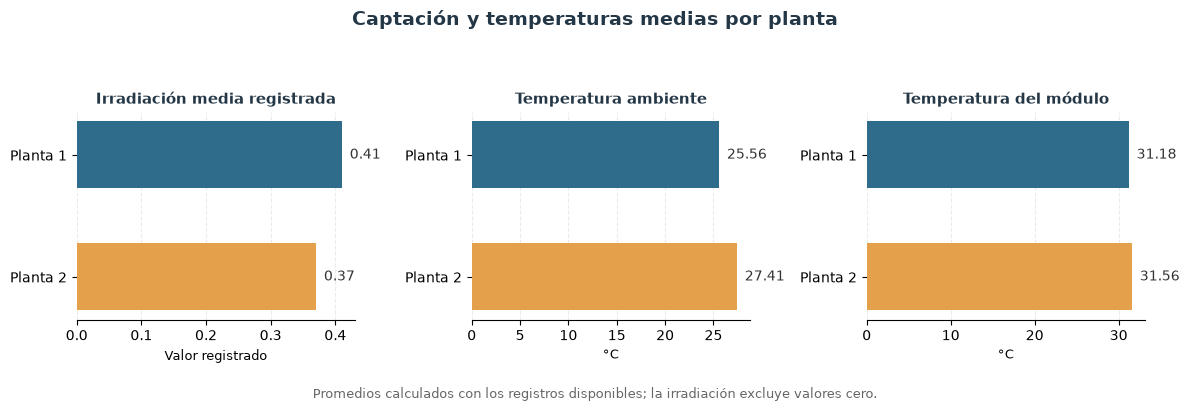

In [23]:
# ── Comparación de captación por planta ─────────

metricas = [
    ('irradiacion_wh_m2', 'Irradiación media registrada', 'Valor registrado'),
    ('temperatura_ambiente_c', 'Temperatura ambiente', '°C'),
    ('temperatura_modulo_c', 'Temperatura del módulo', '°C')
]

colores = {
    'Planta 1': '#2F6B8A',
    'Planta 2': '#E5A04B'
}

fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    columna, titulo, unidad = metrica
    valores = resultado_captacion[columna]

    for posicion, planta in enumerate(valores.index):
        valor = valores.loc[planta]
        eje.barh(
            posicion,
            valor,
            color=colores.get(planta, '#777777'),
            height=0.55
        )
        eje.text(
            valor,
            posicion,
            f'  {valor:.2f}',
            va='center',
            fontsize=10,
            color='#333333'
        )

    eje.set_title(titulo, fontsize=11, weight='bold', color='#243746')
    eje.set_xlabel(unidad, fontsize=9)
    eje.set_yticks(range(len(valores.index)))
    eje.set_yticklabels(valores.index)
    eje.invert_yaxis()
    eje.spines['top'].set_visible(False)
    eje.spines['right'].set_visible(False)
    eje.spines['left'].set_visible(False)
    eje.grid(axis='x', linestyle='--', alpha=0.25)
    eje.set_axisbelow(True)

fig.suptitle(
    'Captación y temperaturas medias por planta',
    fontsize=14,
    weight='bold',
    color='#243746'
)
fig.text(
    0.5,
    0.01,
    'Promedios calculados con los registros disponibles; la irradiación excluye valores cero.',
    ha='center',
    fontsize=9,
    color='#666666'
)

plt.tight_layout(rect=[0, 0.06, 1, 0.90])
plt.show()

### 2.1 Insight 5

La irradiación media registrada es algo menor en Planta 2 (**0,37 frente a 0,42**), pero la temperatura media del módulo es prácticamente igual (**31,56 °C frente a 31,80 °C**). En este resumen no se observa una señal clara de problema de captación en Planta 2. Conviene comparar con las *fases de conversion e inversion* con la irradiacion antes de descartar una anomalía.

_____________________________________________________________

### 2.2 Distribución por hora

La captacion solar del inverter en cada hora en cada planta


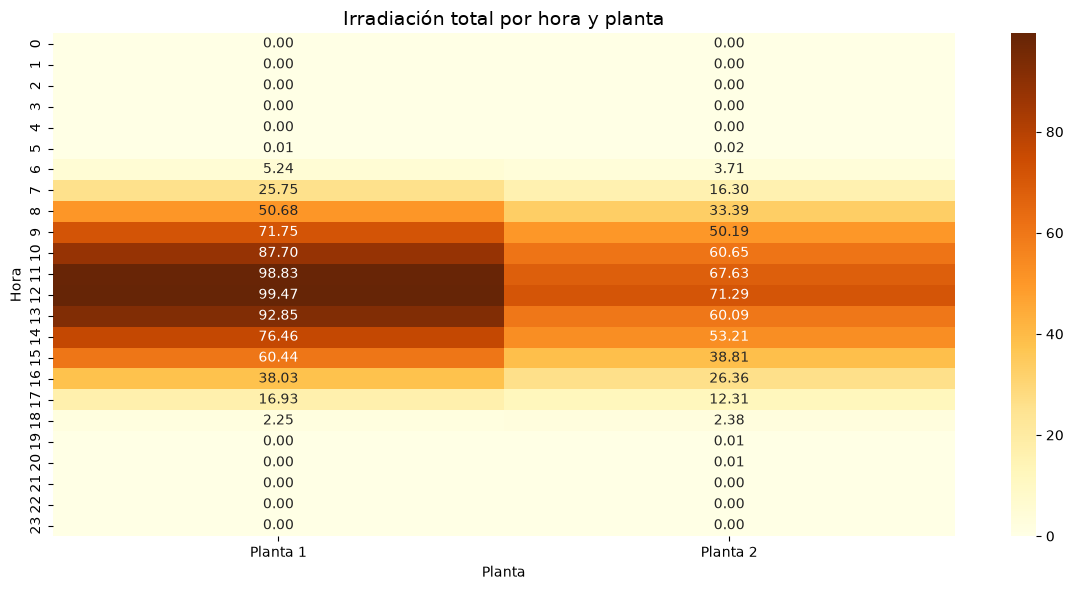

In [24]:
# tabla cruza con las sumas de los tramos de 15 minutos de luz solar para comparacion por hora
temp_hora = pd.crosstab(
    captacion['hora'],
    captacion['id_planta'],
    values=captacion['irradiacion_wh_m2'],
    aggfunc='sum'
)

plt.figure(figsize=(12, 6))
sns.heatmap(temp_hora, annot=True, fmt='.2f', cmap='YlOrBr')
plt.title('Irradiación total por hora y planta', fontsize=14)
plt.xlabel('Planta')
plt.ylabel('Hora')
plt.tight_layout()
plt.show()

## 3. Palanca 3-4: Generación DC y AC

- ¿Cuál es la relación entre irradiación y generación de DC/AC? [1]
- ¿Se ve afectada en algún momento por la temperatura ambiente o del módulo? [2]
- ¿Es similar en ambas plantas? [3]


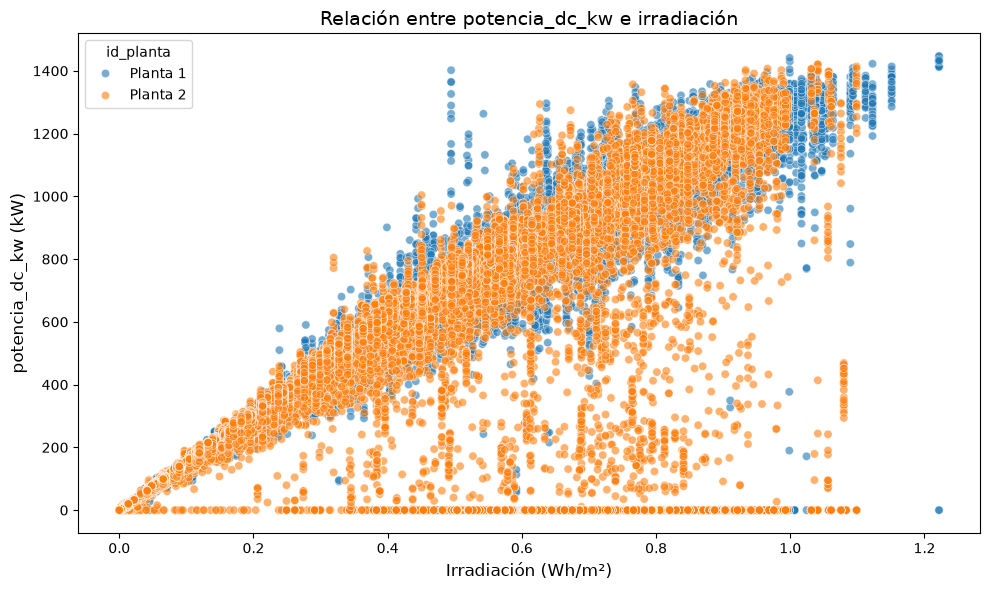

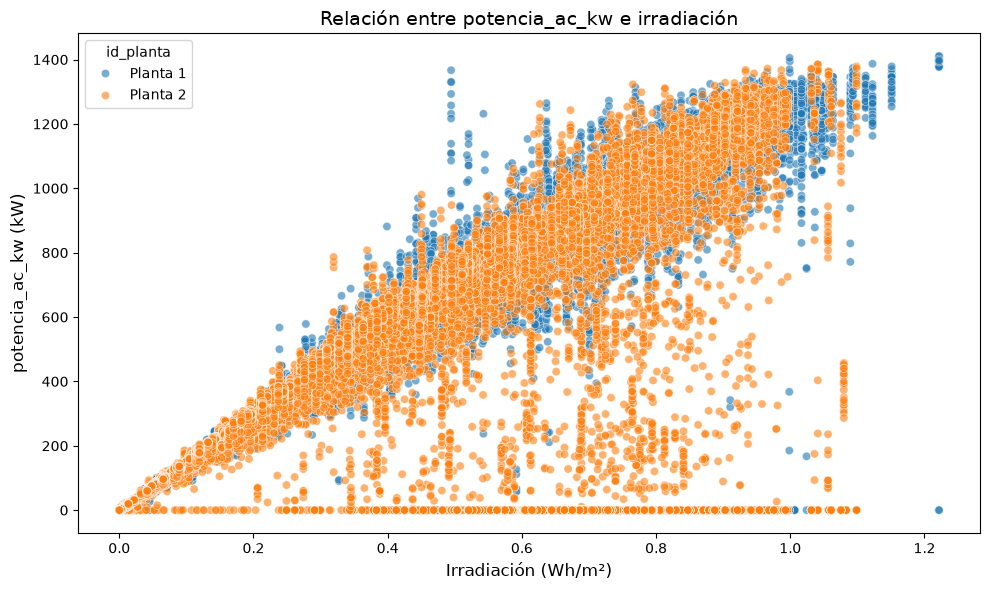

In [25]:
# Correlación entre potencia DC/AC e irradiación

df_grafico = df.reset_index(drop=True)
cols = ['potencia_dc_kw', 'potencia_ac_kw']

for n in cols:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df_grafico,
        x='irradiacion_wh_m2',
        y=n, #cada potencia
        hue='id_planta',
        alpha=0.6
    )
    plt.title(f'Relación entre {n} e irradiación', fontsize=14)
    plt.xlabel('Irradiación (Wh/m²)', fontsize=12)
    plt.ylabel(f'{n} (kW)', fontsize=12)
    plt.tight_layout()
    plt.show()



### 3.1 Insight 6. Caídas de potencia en Planta 2 compatibles con paradas

La relación entre irradiación y potencia muestra caídas puntuales de potencia DC y AC en Planta 2, incluso cuando hay irradiación. El patrón es consistente con posibles paradas o indisponibilidad de inversores, aunque el gráfico por sí solo no confirma la causa.

Se identificara cuándo ocurren esas caídas, qué inversores están afectados y cuánto duran; después, contrastarlas con registros de operación para estimar la energía perdida y decidir si hace falta una inspección en planta.

______________________________________________________________________________________________________

- ¿Cómo se distribuye a lo largo del día? [4]
- ¿Es constante a lo largo de los días? [5]
- ¿Es constante en todos los inverters? [6]
- ¿Ha habido momentos de fallos? [7]

In [26]:
# Dataframe en agregacion con planta, fecha, hora, con la media de potencia_dc_kw y de potencia_ac_kw
# para poder ver la distribucion horararia a lo largo del dia

df['fecha'] = df.index.date
df_analisis_horario = df.groupby(['id_planta','fecha','hora']).agg({
    'potencia_dc_kw': 'mean',
    'potencia_ac_kw': 'mean'
}).reset_index()



In [27]:
# ── Función de potencia por hora y día ─────────

def graficar_horas_por_dia(datos, planta, columna, etiqueta, color, n_columnas=2):
    tabla = datos.loc[datos['id_planta'] == planta].copy()
    tabla['fecha'] = pd.to_datetime(tabla['fecha']).dt.normalize()

    # fechas en columnas, horas en filas: un panel por día
    matriz = tabla.pivot_table(
        index='hora',
        columns='fecha',
        values=columna,
        aggfunc='mean'
    )

    horas = list(matriz.index)
    fechas = list(matriz.columns)
    n_filas = int(np.ceil(len(fechas) / n_columnas))

    fig, ejes = plt.subplots(
        n_filas,
        n_columnas,
        figsize=(12, 2.4 * n_filas),
        sharex=True,
        sharey=True,
        squeeze=False
    )
    ejes = ejes.flatten()

    # asegura enteros: con horas como texto, las barras se centran en 0,1,2... y las marcas se desalinean
    horas = [int(hora) for hora in matriz.index]

    for posicion, fecha in enumerate(fechas):
        eje = ejes[posicion]
        eje.bar(horas, matriz[fecha], color=color, width=0.8, align='center')
        eje.set_title(fecha.strftime('%Y-%m-%d'), fontsize=9, weight='bold')
        eje.grid(axis='y', linestyle='--', alpha=0.25)
        eje.set_axisbelow(True)
        eje.set_xticks(range(0, 24, 3))
        eje.set_xticklabels(range(0, 24, 3), ha='center')
        eje.set_xlim(-0.5, 23.5)
        eje.margins(x=0)
        eje.tick_params(labelsize=7, labelbottom=True, labelrotation=0)

    for posicion in range(len(fechas), len(ejes)):
        fig.delaxes(ejes[posicion])

    # con ejes compartidos basta marcar las horas una vez
    ejes[0].set_xticks(range(0, 24, 3))

    fig.suptitle(f'{etiqueta} por hora y día | {planta}', fontsize=13, weight='bold')
    fig.supxlabel('Hora del día', fontsize=9)
    fig.supylabel(etiqueta, fontsize=9)
    fig.tight_layout(rect=[0, 0.01, 1, 0.96])
    plt.show()

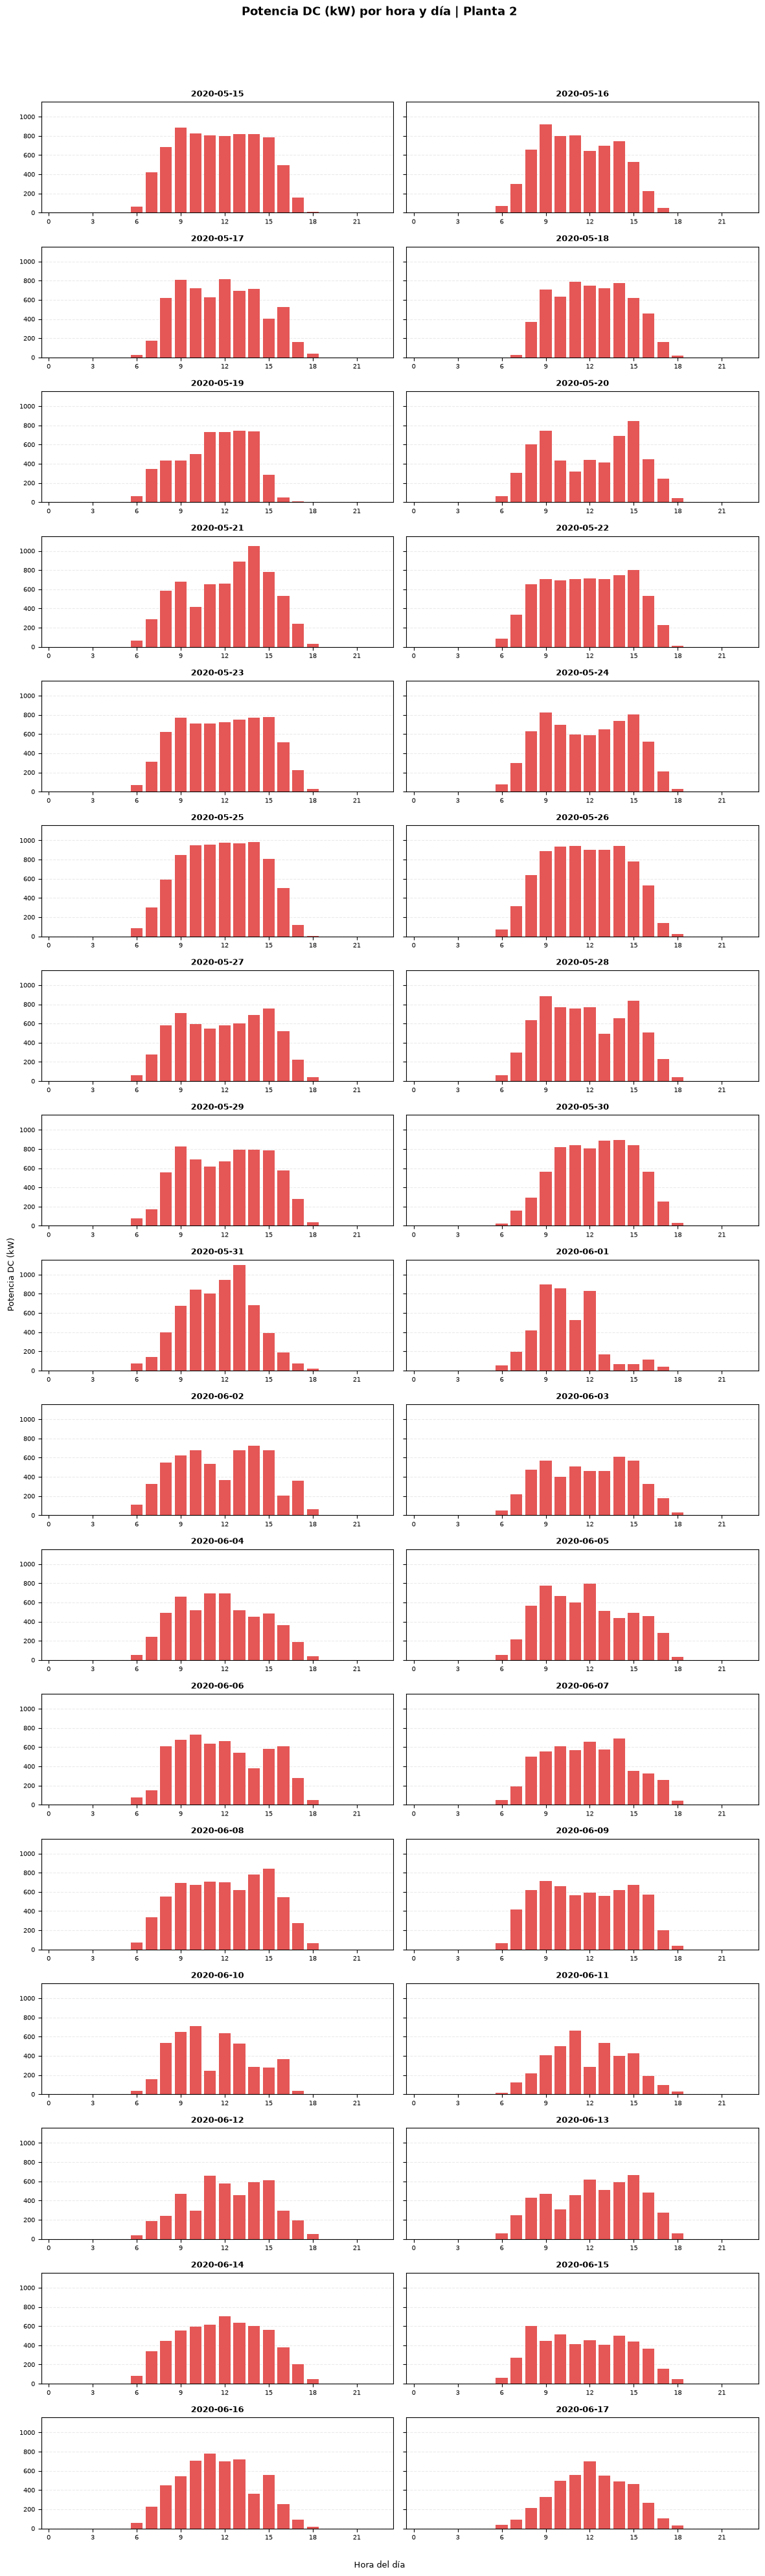

In [28]:
graficar_horas_por_dia(
    df_analisis_horario,
    'Planta 2',
    'potencia_dc_kw',
    'Potencia DC (kW)',
    '#e45756'
)

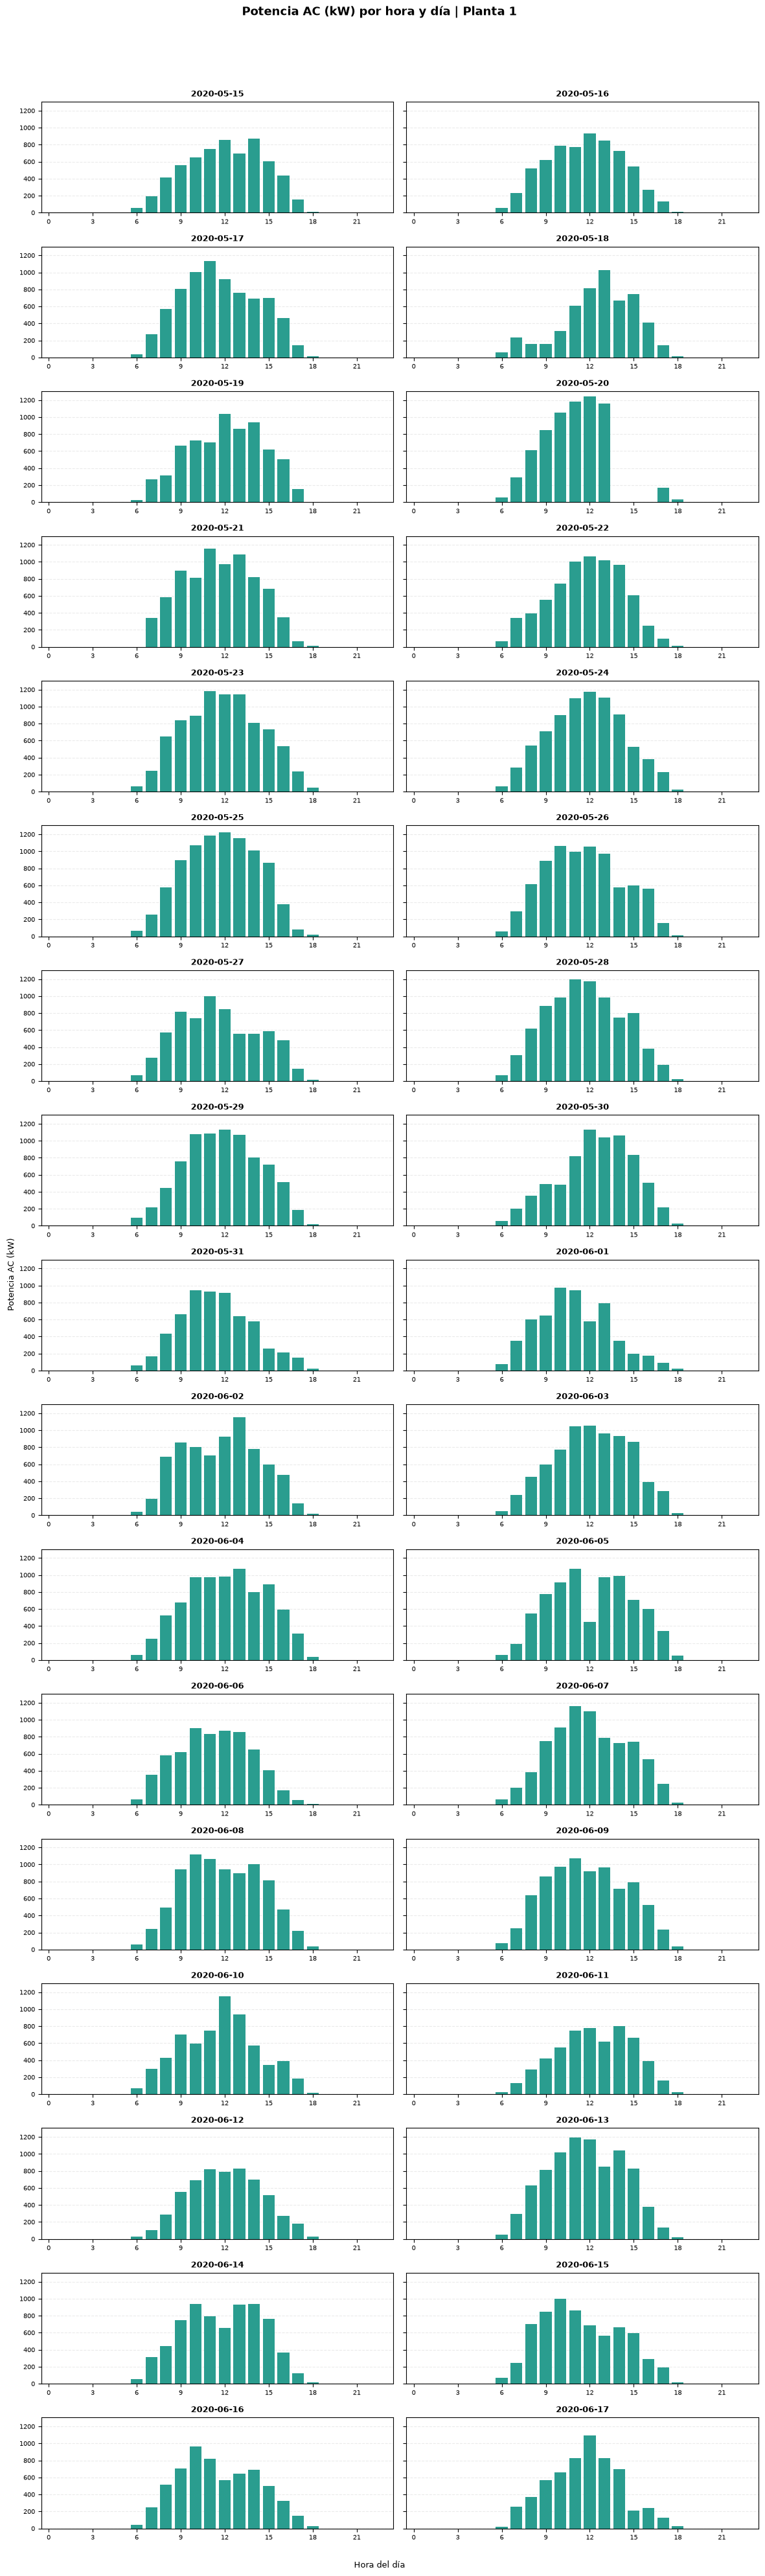

In [29]:
graficar_horas_por_dia(
    df_analisis_horario,
    'Planta 1',
    'potencia_ac_kw',
    'Potencia AC (kW)',
    '#2a9d8f'
)

### 3.2 Análisis horario de potencia

Al revisar el comportamiento por hora de la potencia DC y AC en los 34 días, se identificaron los días donde las caídas son más marcadas respecto a la forma esperada de la curva. Sobre esos días se revisará el comportamiento de cada inversor.

Para elegir los días se cuenta, en cada jornada, **cuántos tramos de 15 minutos tiene un inversor en cero** mientras el resto de la planta está produciendo. Esa suma se pasa a horas y se ordena de mayor a menor. El cálculo ignora la noche, porque solo mira los tramos en que el parque genera.

Ese criterio encuentra los parones aunque duren dos horas, cosa que un promedio diario esconde, y no se apoya en umbrales elegidos a mano. Los cinco días con más inversor-horas caídas de cada planta son los que pasan al detalle por inversor.

In [34]:
# ── Días con más inversor-horas caídas ─────────

partes = []
for archivo in ['Planta1_Generacion.pkl', 'Planta2_Generacion.pkl']:
    partes.append(pd.read_pickle(ANALITICO / archivo))

gen = pd.concat(partes, ignore_index=True)
gen['fecha'] = gen['fecha_hora'].dt.normalize()

# el parque produce si la mediana de sus inversores en ese instante es positiva
gen['referencia'] = gen.groupby(['id_planta', 'fecha_hora'])['potencia_ac_kw'].transform('median')
gen['caido'] = (gen['referencia'] > 0) & (gen['potencia_ac_kw'] <= 0)

dias = (
    gen.groupby(['id_planta', 'fecha'])
    .agg(inversores=('id_inversor', 'nunique'), tramos_caidos=('caido', 'sum'))
    .reset_index()
)
dias['inversor_horas_caidas'] = dias['tramos_caidos'] * 0.25
dias = dias.sort_values(['id_planta', 'inversor_horas_caidas'], ascending=[True, False])

In [35]:
# ── Cinco peores días de cada planta ─────────

peores = dias.groupby('id_planta', group_keys=False).head(5).copy()
peores['fecha'] = peores['fecha'].dt.strftime('%Y-%m-%d')

(
    peores.style
    .background_gradient(subset=['inversor_horas_caidas'], cmap='Reds')
    .format({'inversor_horas_caidas': '{:.2f}'})
    .set_caption('Cinco días con más inversor-horas caídas por planta')
)

,id_planta,fecha,inversores,tramos_caidos,inversor_horas_caidas
23,Planta 1,2020-06-07,22,33,8.25
30,Planta 1,2020-06-14,22,24,6.00
12,Planta 1,2020-05-27,22,5,1.25
0,Planta 1,2020-05-15,22,3,0.75
3,Planta 1,2020-05-18,22,2,0.50
57,Planta 2,2020-06-07,22,202,50.50
56,Planta 2,2020-06-06,22,197,49.25
58,Planta 2,2020-06-08,22,177,44.25
41,Planta 2,2020-05-22,18,176,44.00
42,Planta 2,2020-05-23,18,158,39.50


In [36]:
# ── Registros de los días elegidos ─────────

claves = peores[['id_planta', 'fecha']].copy()
claves['fecha'] = pd.to_datetime(claves['fecha'])

# el criterio automático usa medias horarias y deja fuera caídas cortas, así que se suman días revisados a mano
manual = pd.DataFrame({
    'id_planta': ['Planta 1'],
    'fecha': pd.to_datetime(['2020-05-20'])
})

claves = pd.concat([claves, manual]).drop_duplicates()

df_problemas = df.reset_index().copy()
df_problemas['fecha_dia'] = pd.to_datetime(df_problemas['fecha_hora']).dt.normalize()
df_problemas = df_problemas.merge(
    claves.rename(columns={'fecha': 'fecha_dia'}),
    on=['id_planta', 'fecha_dia'],
    how='inner'
)

### 3.3 Insight 7

Las caídas se concentran en **Planta 2**. Sus cinco peores días van de **39,50 a 50,50** inversor-horas caídas, entre cinco y seis veces más que los de **Planta 1**, que van de **0,50 a 8,25**. El **7 de junio** es el peor día en las dos plantas, con **50,50 horas en Planta 2** y **8,25 en Planta 1**.

En **Planta 2** los tres peores días son consecutivos, **6, 7 y 8 de junio**, con **44 a 50 horas** caídas cada uno. Tres días seguidos apuntan a una causa común, red o comunicaciones, más que a fallos aislados de equipos.

El **22 y el 23 de mayo** solo reportan **18 de los 22 equipos**, así que las horas contadas son las de los 18 presentes. Los cuatro ausentes no suman y es probable que la pérdida real de esos dos días sea mayor.

En **Planta 1** el máximo es de **8,25 horas el 7 de junio** y el resto no pasa de 6. Acumulado en los 34 días, cinco equipos de Planta 2 suman entre **62 y 74 horas** paradas frente a **5,75 del peor de Planta 1**.

El criterio automático trabaja con medias horarias, así que una caída de menos de una hora se diluye y no sube a la lista. Por eso se agrega a mano el **20 de mayo de Planta 1**, donde la curva se corta desde las 14 hasta las 16 y ese día solo hay **76 de 96 ventanas**. El desglose por inversor se hace sobre estos once días.

### 3.4 ¿Es constante en todos los inversores?

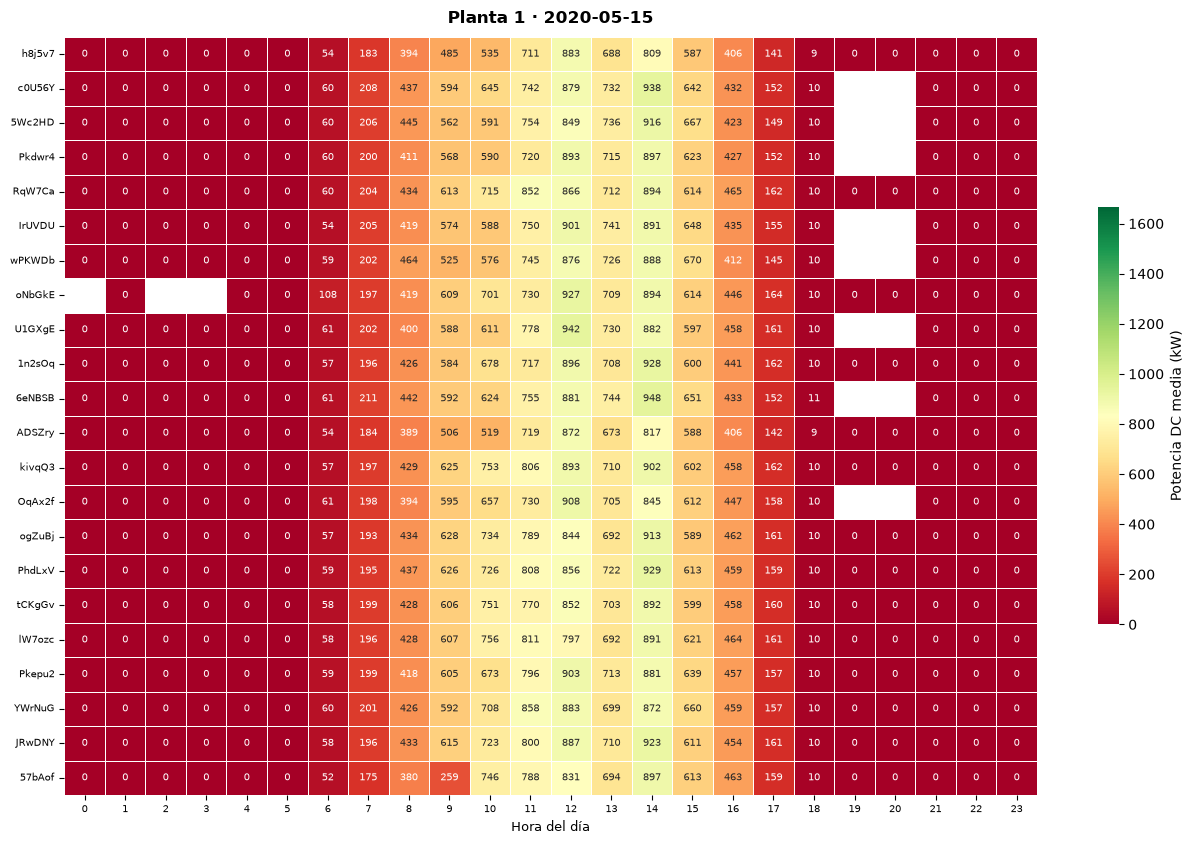

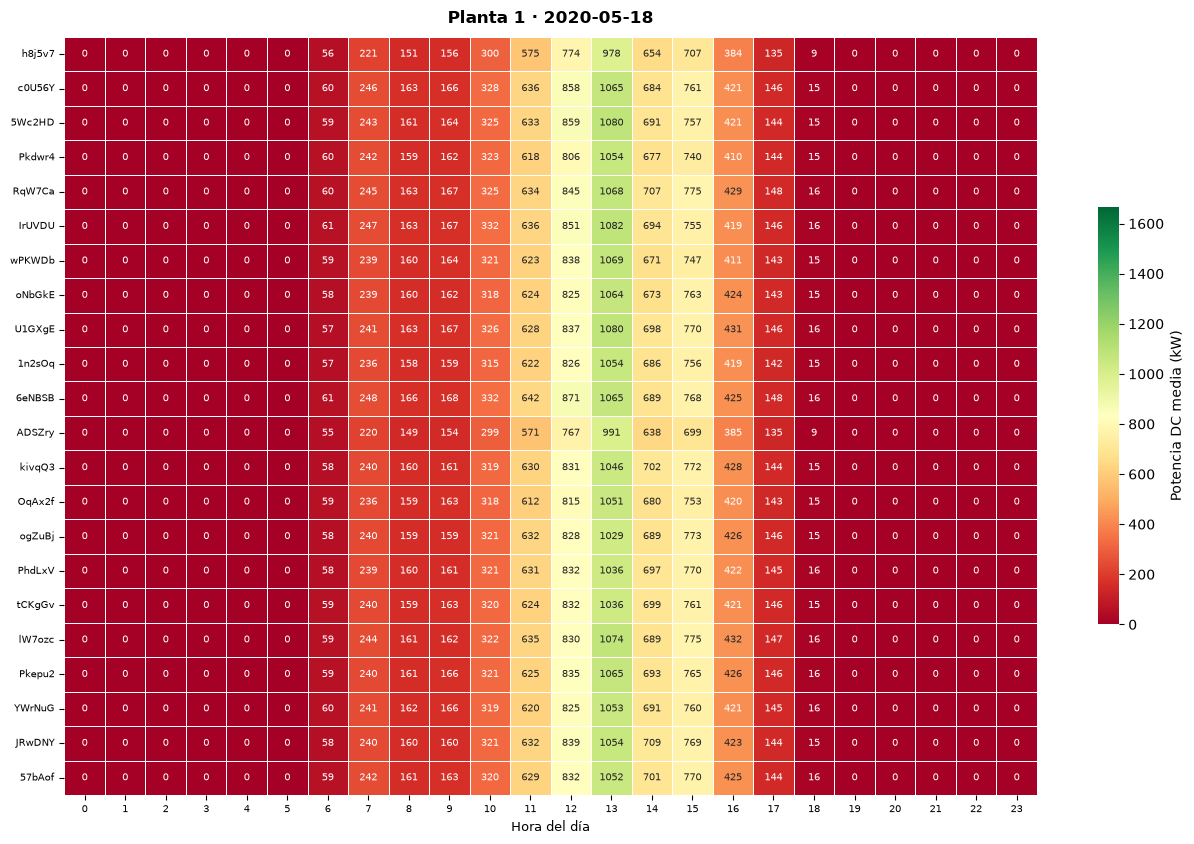

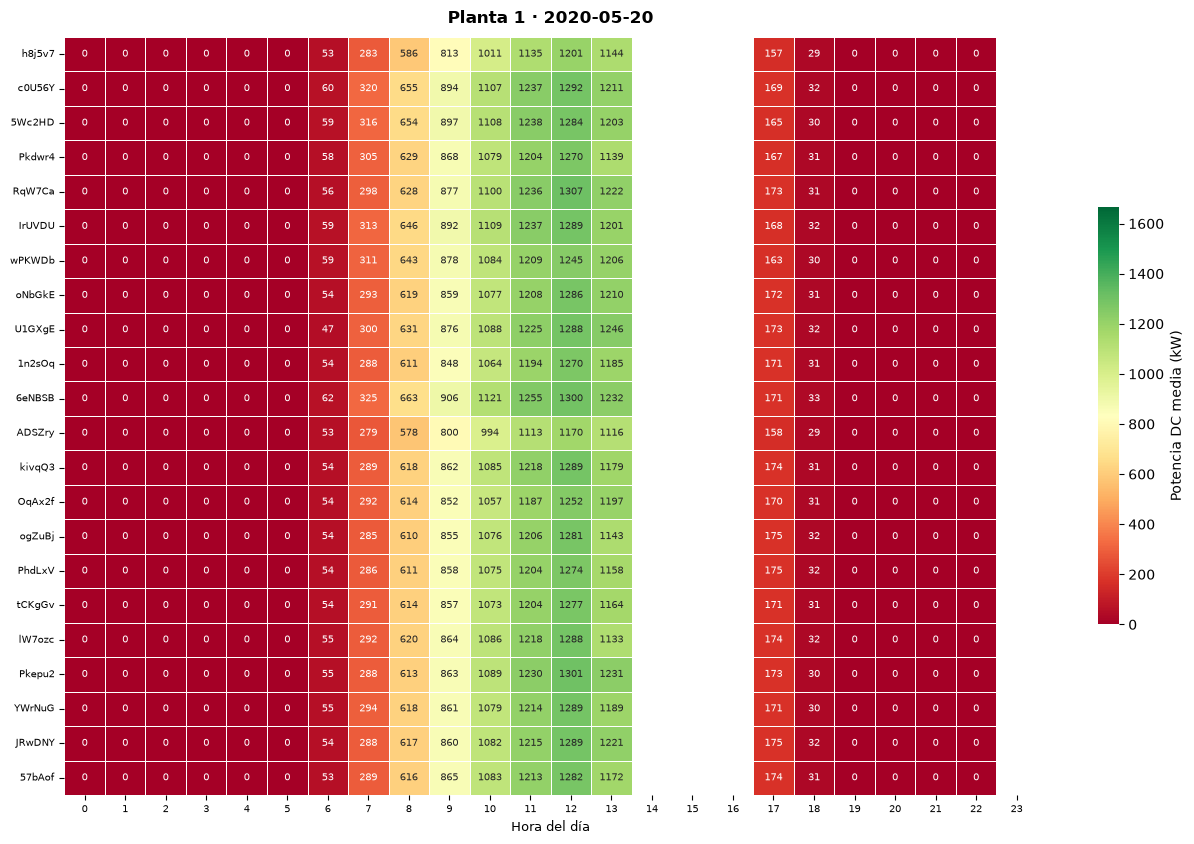

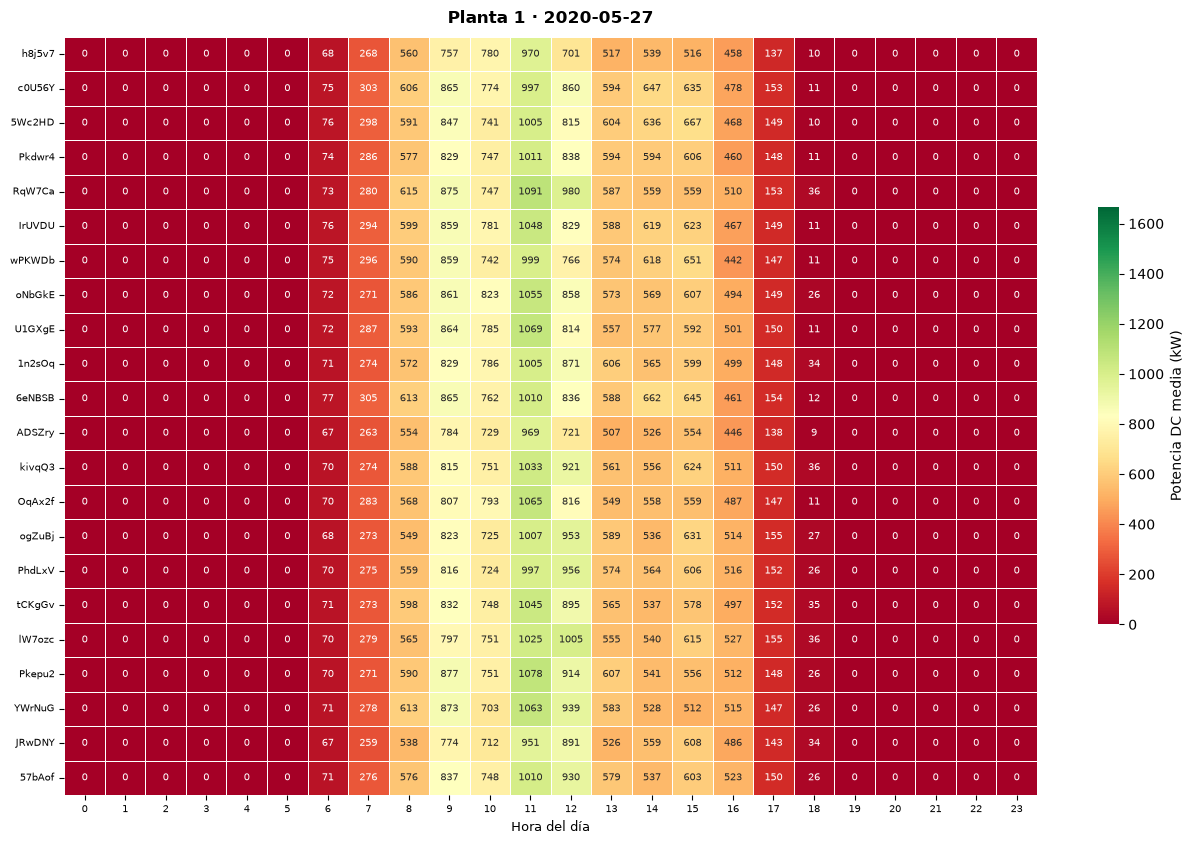

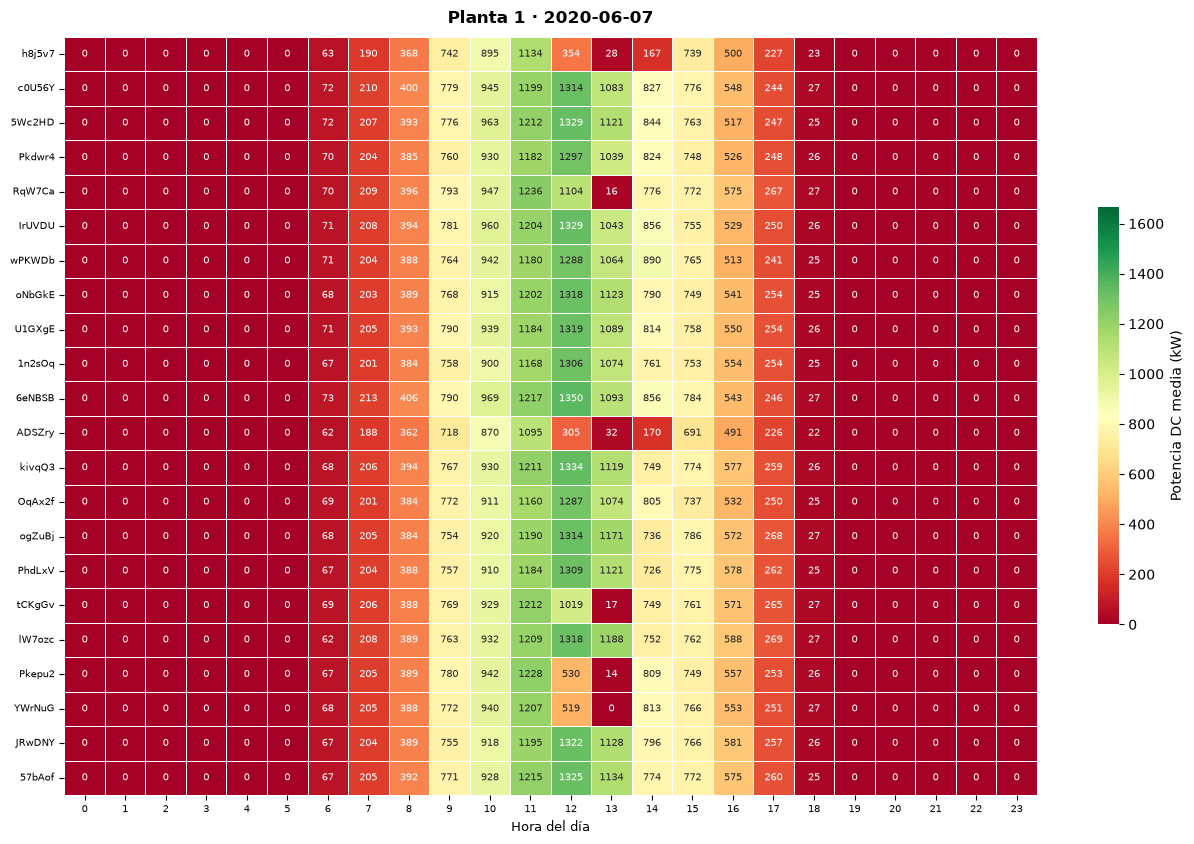

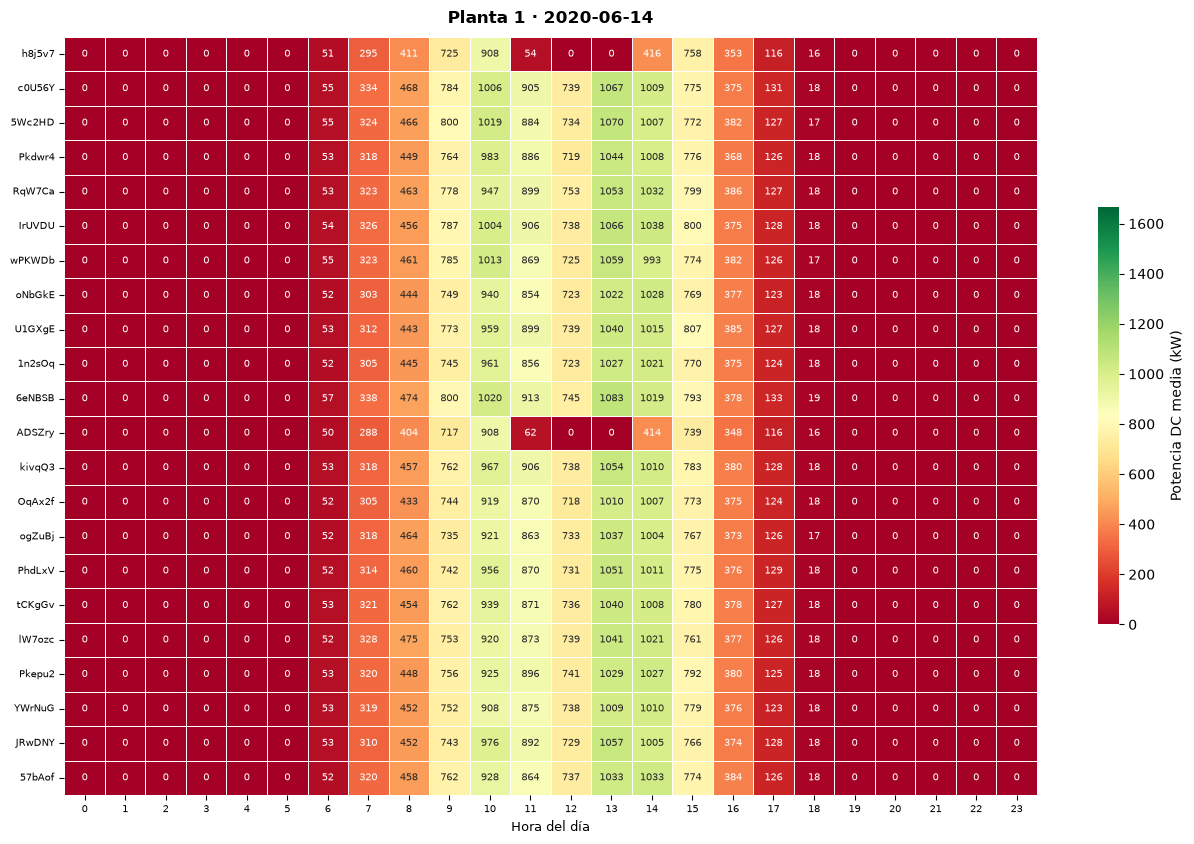

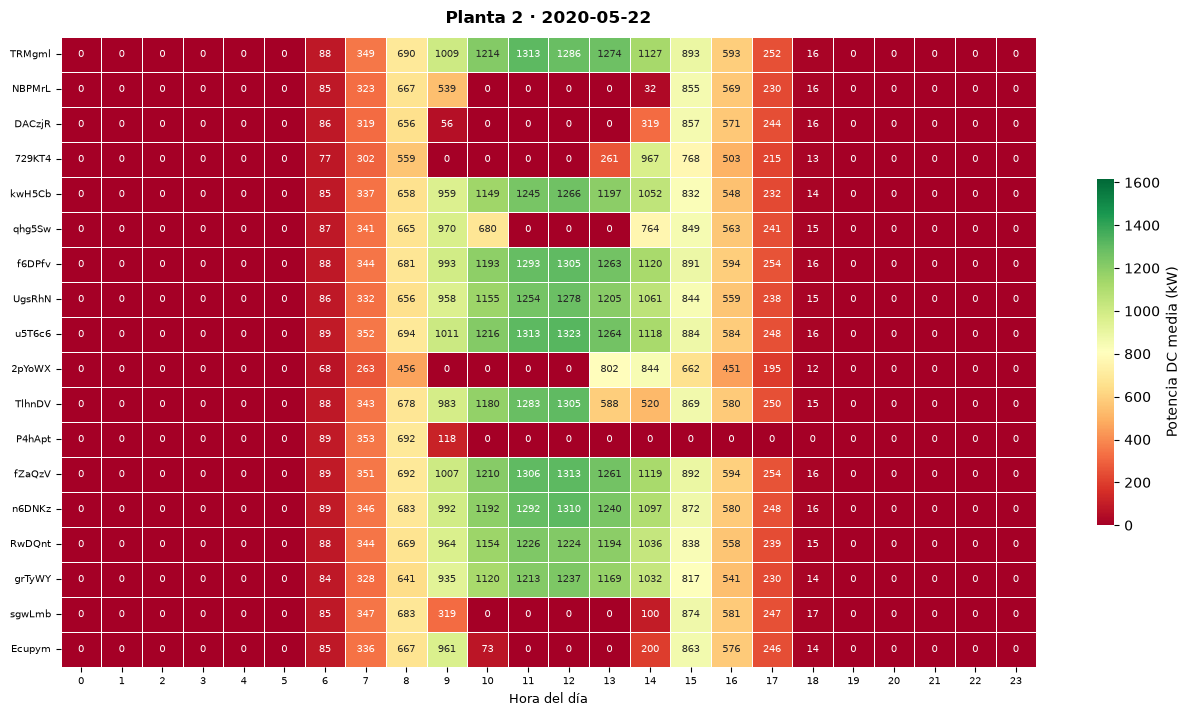

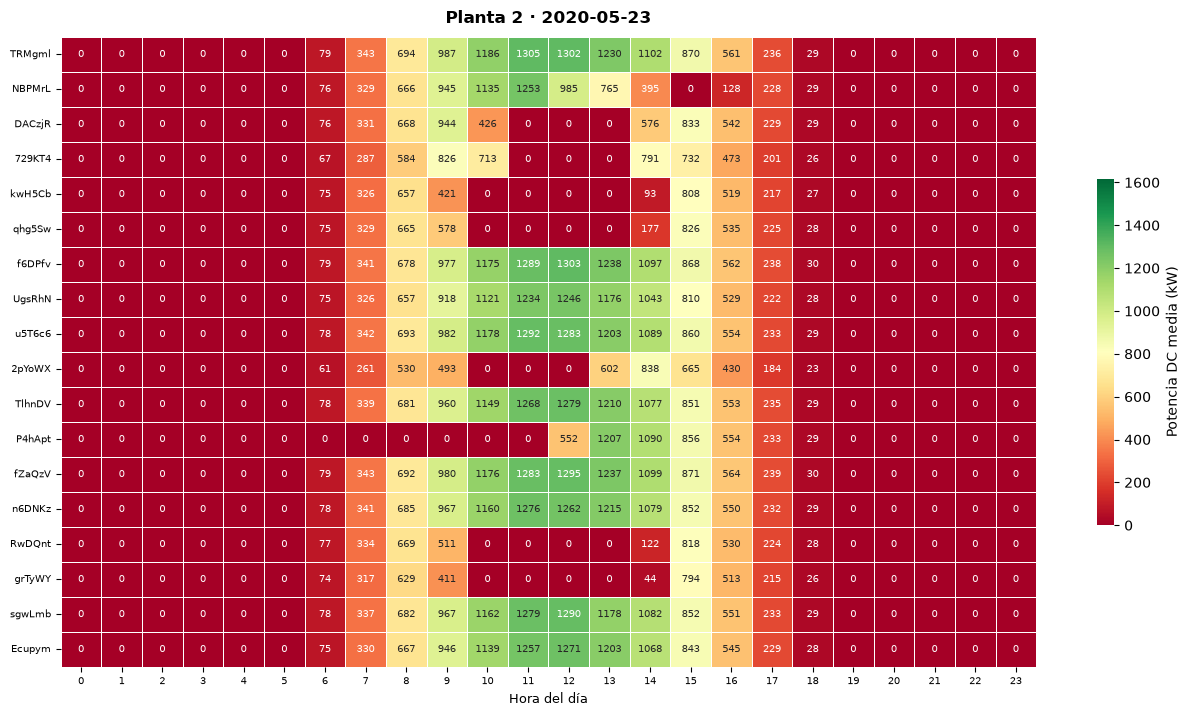

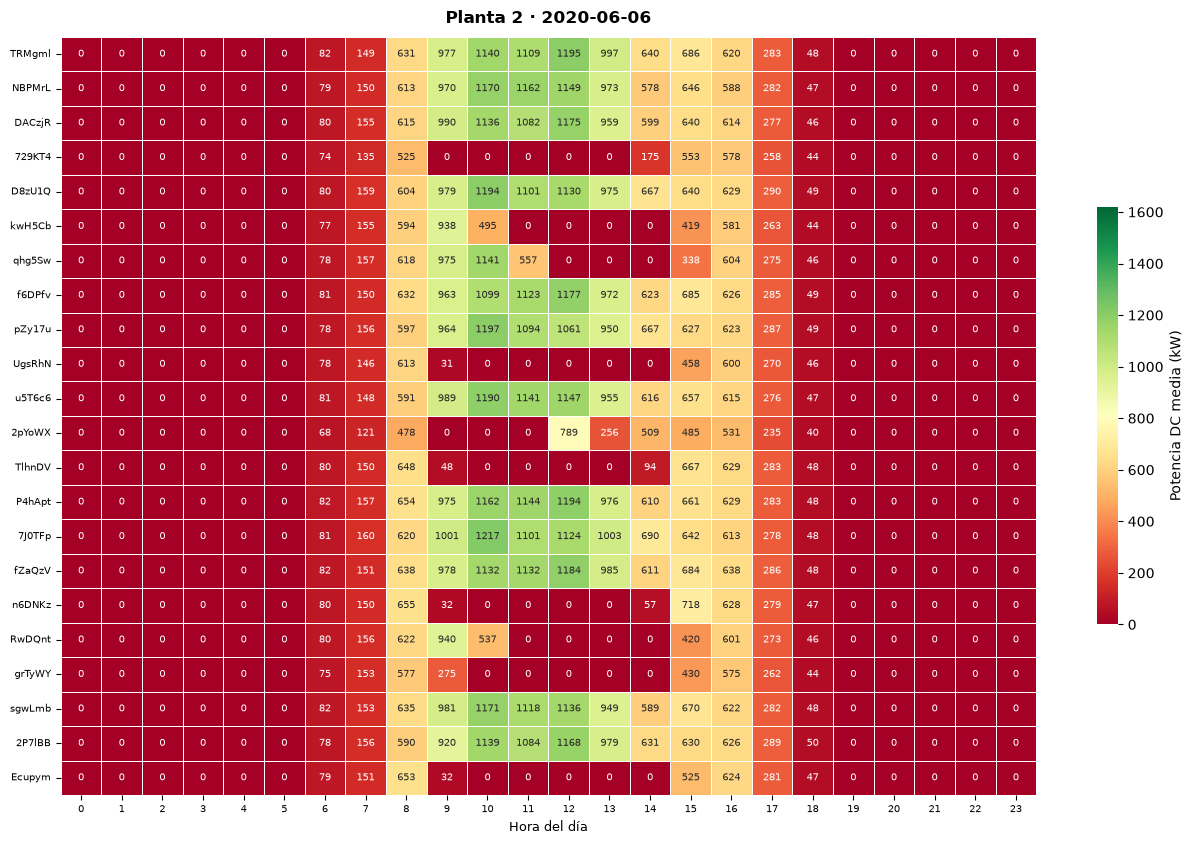

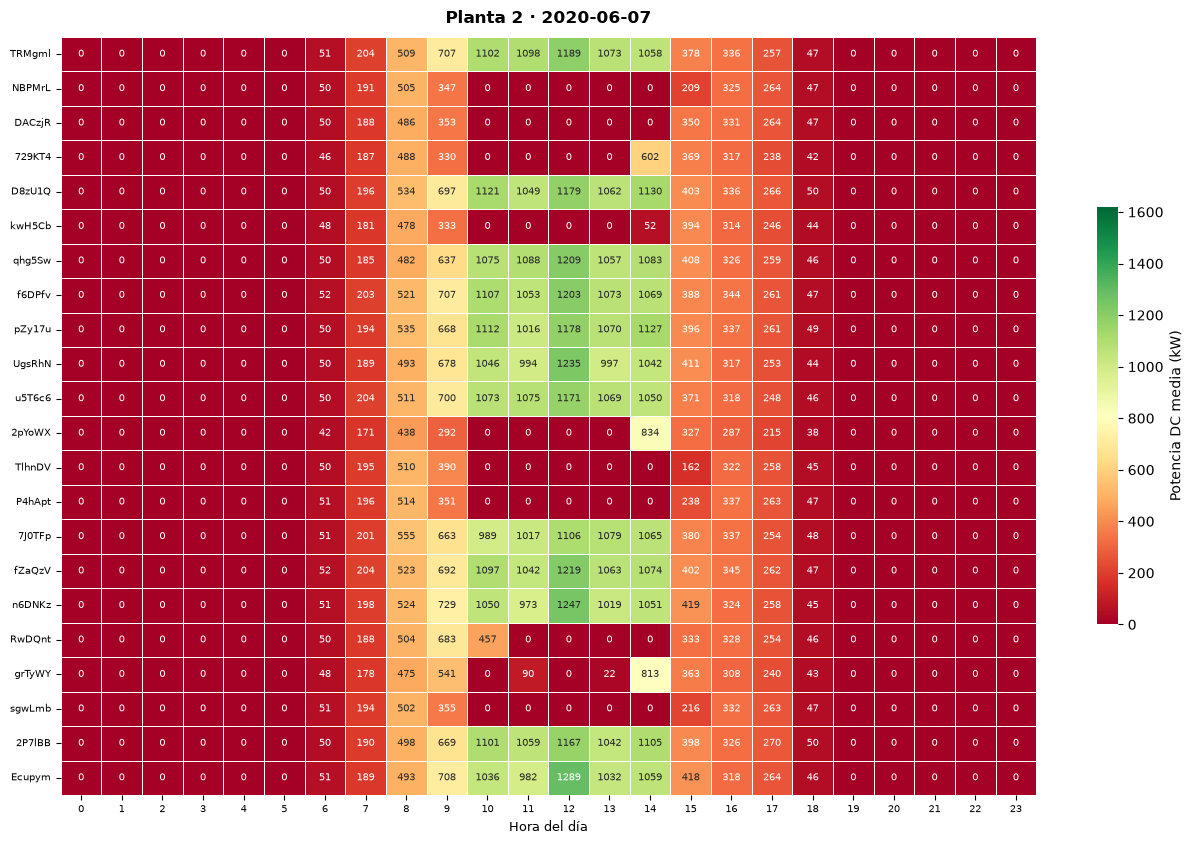

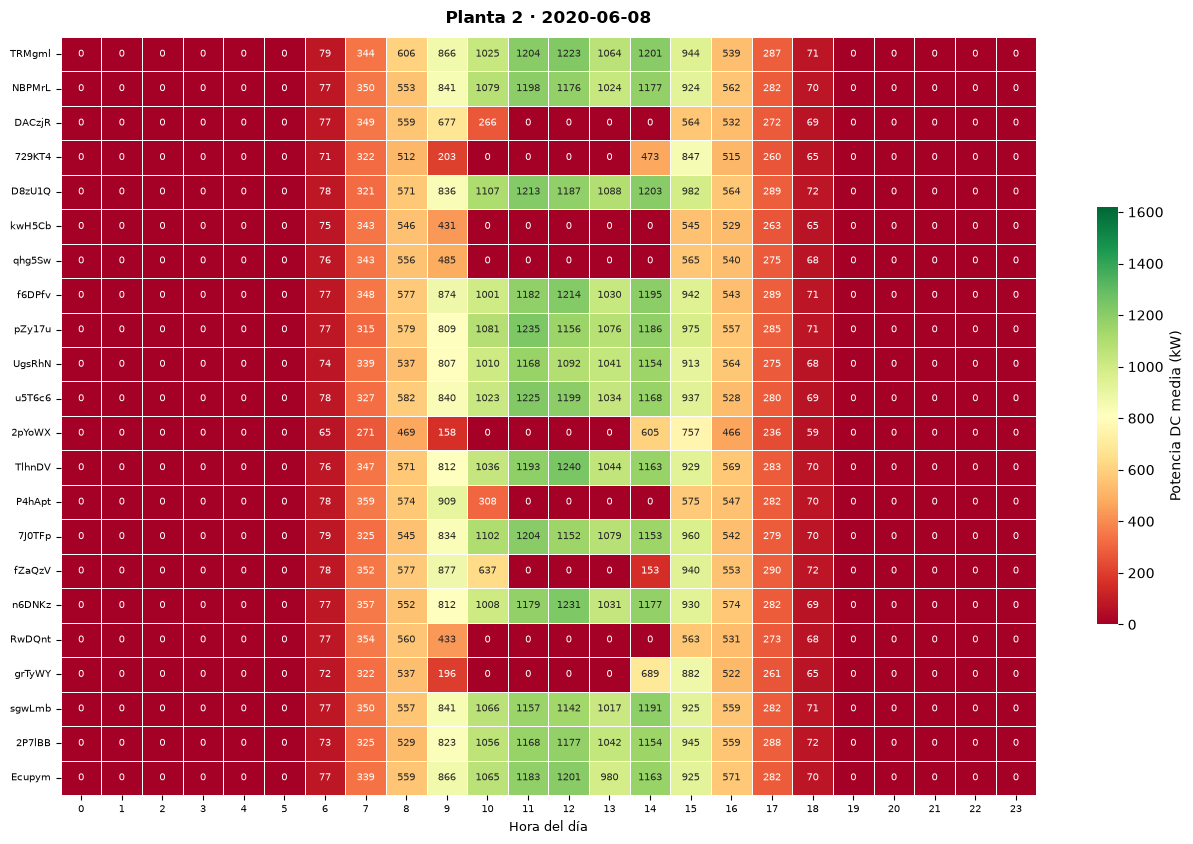

In [38]:
# ── Heatmaps por día e inversor ─────────

# escala fija por planta para que los días se comparen entre sí
vmax = df_problemas.groupby('id_planta')['potencia_dc_kw'].max().to_dict()

for planta in df_problemas['id_planta'].unique():
    df_planta = df_problemas[df_problemas['id_planta'] == planta]

    for fecha in sorted(df_planta['fecha'].unique()):
        df_dia = df_planta[df_planta['fecha'] == fecha]

        pivot = df_dia.pivot_table(
            index='id_inversor', columns='hora',
            values='potencia_dc_kw', aggfunc='mean'
        ).reindex(columns=range(24))

        # el id completo no cabe en el eje, basta el final
        etiquetas = []
        for inversor in pivot.index:
            etiquetas.append(inversor[-6:])

        alto = 0.32 * len(pivot.index) + 1.5

        fig, eje = plt.subplots(figsize=(13, alto))
        sns.heatmap(
            pivot,
            ax=eje,
            cmap='RdYlGn',
            vmin=0,
            vmax=vmax[planta] * 1.15,
            annot=True,
            fmt='.0f',
            annot_kws={'size': 7},
            linewidths=0.4,
            linecolor='white',
            cbar_kws={'label': 'Potencia DC media (kW)', 'shrink': 0.55}
        )

        eje.set_yticklabels(etiquetas, rotation=0, fontsize=7)
        eje.set_xticklabels(range(24), fontsize=7)
        eje.set_title(f'{planta} · {fecha}', fontsize=12, weight='bold', pad=10)
        eje.set_xlabel('Hora del día', fontsize=9)
        eje.set_ylabel('')
        plt.tight_layout()
        plt.show()

## BONUS

- Análisis de lo que sucedió el 7 de junio
- Se guarda un CSV con los fallos y su tipo para revisarlos después con operación


In [69]:
# ── Qué pasó el 7 de junio, con el tablón del notebook ─────────

dia7 = df.copy()
dia7['fecha_dia'] = pd.to_datetime(dia7.index).normalize()
dia7 = dia7.loc[dia7['fecha_dia'] == pd.Timestamp('2020-06-07')]

print('filas:', len(dia7), 'inversores:', dia7['id_inversor'].nunique())

dia7['en_cero'] = dia7['potencia_ac_kw'] <= 0

tabla = (
    dia7.pivot_table(index='hora', columns='id_planta', values='en_cero', aggfunc='sum')
    .fillna(0)
    .astype(int)
)

#tabla

filas: 4224 inversores: 44


In [70]:
#  Inversores caídos la hora completa

por_hora = (
    dia7.groupby(['hora', 'id_planta', 'id_inversor'])['en_cero']
    .mean()
    .reset_index()
)
por_hora['caido'] = por_hora['en_cero'] == 1

tabla = por_hora.pivot_table(index='hora', columns='id_planta', values='caido', aggfunc='sum')
#tabla.loc[7:18]

____________________________________________________________________________________

#### DataFrame de Fallos a Analizar

In [ ]:
# ── Fallos de los días analizados ─────────
# potencia_cero  el parque produce y el equipo marca cero
# potencia_baja  el equipo produce menos del 70 % de la mediana de su planta
# operativo      produce en línea con el parque
# sin_sol        el parque entero está en cero, es de noche
# sin_dato       no hay lectura del parque

fallos = df_problemas[[
    'id_planta', 'fecha_dia', 'id_inversor', 'hora', 'potencia_dc_kw'
]].copy()
fallos = fallos.rename(columns={'fecha_dia': 'fecha'})

fallos['referencia_parque'] = (
    fallos.groupby(['id_planta', 'fecha', 'hora'])['potencia_dc_kw'].transform('median')
)

fallos['tipo_fallo'] = 'operativo'
fallos.loc[fallos['potencia_dc_kw'] < 0.7 * fallos['referencia_parque'], 'tipo_fallo'] = 'potencia_baja'
fallos.loc[fallos['potencia_dc_kw'] <= 0, 'tipo_fallo'] = 'potencia_cero'
fallos.loc[fallos['referencia_parque'] <= 0, 'tipo_fallo'] = 'sin_sol'
fallos.loc[fallos['referencia_parque'].isna(), 'tipo_fallo'] = 'sin_dato'

fallos = fallos[['id_planta', 'fecha', 'id_inversor', 'hora', 'potencia_dc_kw', 'tipo_fallo']]
fallos.to_csv(RESULTADOS / 'fallos.csv', index=False)

# fallos['tipo_fallo'].value_counts()

tipo_fallo
sin_sol          10116
operativo         9316
potencia_baja     1206
potencia_cero     1168
Name: count, dtype: int64

## Conclusión

Las **34 jornadas** no muestran un problema de captación. Planta 2 recibe **12 % menos irradiación** que Planta 1 y su módulo está a la misma temperatura, así que la diferencia es de ubicación y no de equipos.

La pérdida está en la disponibilidad de los inversores y se concentra en **Planta 2**. Sus peores días pierden **entre cinco y seis veces más inversor-horas** que Planta 1, y sus **cinco equipos más afectados** suman entre **62 y 74 horas** paradas en 34 días, frente a **5,75 horas** del peor de Planta 1.

El 7 de junio se revisó hora por hora. Entre las **10 y las 14**, Planta 2 tuvo entre **6 y 10 de sus 22 inversores** en cero la hora completa, mientras Planta 1 no pasó de un equipo en un solo tramo. El evento es de Planta 2, empieza y termina en horas exactas, y apunta a un grupo de equipos que se detiene junto.